# Challenge 1: The banknote-authentication data set problem

We will perform a nearly realistic analysis of the data set bank note authentication that can be downloaded from this [link](https://archive.ics.uci.edu/dataset/267/banknote+authentication) or from the [github repo](https://github.com/LorenzoTonet/Intro_to_ML_26-27/blob/main/data/data_banknote_authentication.txt)

## Data set description

Data were extracted from images that were taken from genuine and forged banknote-like specimens. For digitization, an industrial camera usually used for print inspection was used. The final images have 400x 400 pixels. Due to the object lens and distance to the investigated object gray-scale pictures with a resolution of about 660 dpi were gained. Wavelet Transform tool were used to extract features from images.
These features are:
1. variance of Wavelet Transformed image (continuous) 
2. skewness of Wavelet Transformed image (continuous) 
3. curtosis of Wavelet Transformed image (continuous) 
4. entropy of image (continuous) 
5. class (integer)

## Task description
We have a binary classification problem. The assignment can be divided in several parts:
    
    1. Load the data and pretreatment.
    2. Data exploring by Unsupervised Learning techniques.
    3. Construction of several models of Supervised Learning.
    4. Assessment and evaluation

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk

### 1. Data pretreatment

Load the data and look at it: It is needed some kind of scaling? Why? Are the data points sorted in the original data set? Can it generate problems? How can this be solved?

In [3]:
path_csv = "../data/data_banknote_authentication.csv"
column_names = ["variance", "skewness", "curtosis", "entropy", "class"]
df = pd.read_csv(path_csv, header=None, names=column_names)

df.head()


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [4]:
feature_columns = column_names[:-1]

assert df.shape[1] == len(column_names)
assert df[feature_columns].notna().all().all()
assert df["class"].isin([0, 1]).all()

print(f"Shape: {df.shape}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print("Class distribution:")
print(df["class"].value_counts().sort_index())
print("Feature summary:")
display(df[feature_columns].describe().T)


Shape: (1372, 5)
Duplicate rows: 24
Class distribution:
class
0    762
1    610
Name: count, dtype: int64
Feature summary:


,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495


In [5]:
features = df[feature_columns]
q1 = features.quantile(0.25)
q3 = features.quantile(0.75)
iqr = q3 - q1
outlier_mask = features.lt(q1 - 1.5 * iqr) | features.gt(q3 + 1.5 * iqr)

print("Potential outliers by feature:")
print(outlier_mask.sum())
print(f"Rows with at least one potential outlier: {outlier_mask.any(axis=1).sum()}")


Potential outliers by feature:
variance     0
skewness     0
curtosis    59
entropy     33
dtype: int64
Rows with at least one potential outlier: 92


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer

# Keep the target unchanged and transform only the skewed input features.
preprocessor = ColumnTransformer(
    [("power", PowerTransformer(method="yeo-johnson"), ["curtosis", "entropy"])],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
X = pd.DataFrame(
    preprocessor.fit_transform(features),
    columns=feature_columns,
    index=df.index,
)
y = df["class"].copy()

print("Skewness before transformation:")
print(features.skew().round(3))
print("Skewness after transformation:")
print(X.skew().round(3))


Skewness before transformation:
variance   -0.149
skewness   -0.394
curtosis    1.089
entropy    -1.022
dtype: float64
Skewness after transformation:
variance    0.055
skewness    0.018
curtosis   -0.149
entropy    -0.394
dtype: float64


In [10]:
from sklearn.model_selection import train_test_split

X = df.drop("class", axis=1)
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### 2. Unsupervised Learning

Use PCA and plot the two first components colouring according with the class. Are the classes linearly separable in this projection? What happens when I applied k-means with two classes in this space? And if I use all the coordinates? Try also t-SNE for projection and DBSCAN for the clustering and comment on the results.

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_raw = X_train.copy()
X_train = (X_train - X_mean) / X_std

In [18]:
class MyPCA:
    """PCA via eigendecomposition of the covariance matrix."""
    #TODO: Implement the PCA algorithm
    def __init__(self):
        self.mean_ = None
        self.scale_ = None
        self.components_ = None
        self.eigenvalues_ = None
        self.explained_variance_ratio_ = None


    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.scale_ = None
        Xc = X - self.mean_
            
        C = Xc.T @ Xc / (X.shape[0] - 1)           # covariance matrix (unbiased)
        eigval, eigvec = np.linalg.eigh(C)         # eigh: symmetric matrix, ascending eigenvalues
        order = np.argsort(eigval)[::-1]           # sort by decreasing eigenvalue
        self.eigenvalues_ = eigval[order]
        self.components_ = eigvec[:, order]        # columns = principal directions
        self.explained_variance_ratio_ = self.eigenvalues_ / self.eigenvalues_.sum()
        return self

    def transform(self, X, k=None):
        Z = (X - self.mean_) @ self.components_
        return Z if k is None else Z[:, :k]

    def inverse_transform(self, Z):
        k = Z.shape[1]
        return Z @ self.components_[:, :k].T + self.mean_

pca = MyPCA().fit(X_train)

Components needed for 95% variance: 3


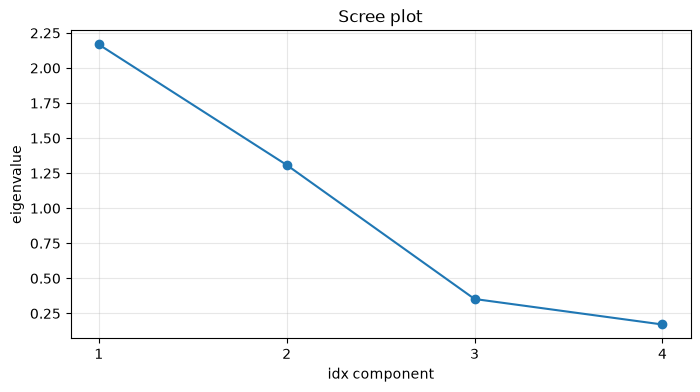

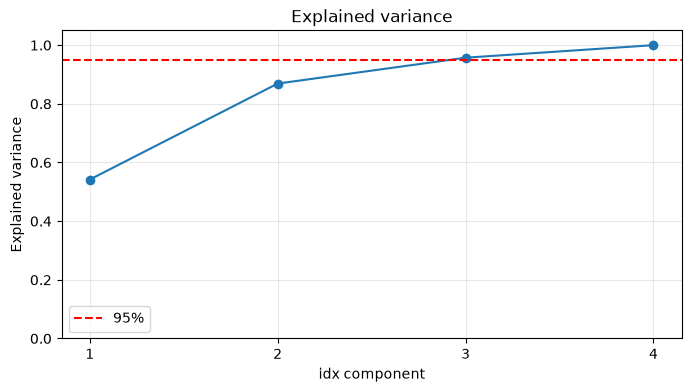

In [20]:
cumulative_var = np.cumsum(pca.explained_variance_ratio_)
threshold = 0.95

k = np.argmax(cumulative_var >= threshold) + 1

print(f"Components needed for {threshold:.0%} variance: {k}")



eigenvalues = pca.eigenvalues_
explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

components = np.arange(1, len(eigenvalues) + 1)

plt.figure(figsize=(8, 4))
plt.plot(components, eigenvalues, marker="o")
plt.xlabel("idx component")
plt.ylabel("eigenvalue")
plt.title("Scree plot")
plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(components, cumulative_var, marker="o")
plt.axhline(y=threshold, linestyle="--", color="red", label="95%")
plt.xlabel("idx component")
plt.ylabel("Explained variance")
plt.title("Explained variance")
plt.ylim(0, 1.05)
plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [23]:
new_X = pca.transform(X_train, k=4)
plt.scatter(new_X[:, 0], new_X[:, 1], c=y, cmap='viridis', alpha=0.7)

KeyError: (slice(None, None, None), slice(None, 4, None))

### 3. Supervised Learning

Generate a subset of the data of 372 elements that would be saved as test set. With the rest of the data generate the following models: Logistic Regression, Decision tree (use the ID3 algorithm), Naive Bayes and k-NN. 

Investigate the effect of regularization (when possible) and use cross validation for setting the hyper-parameters when needed. 

Compare the performances in terms of accuracy, precision, recall and F1-score on the test set. Comment these results at the light of those obtained from the Unsupervised Learning analysis. Could you propose a way to improve these results?     
